# Homework 3: Machine Learning for Classification

**Course**: DataTalks.Club Machine Learning Zoomcamp (2026 Cohort)  
**Dataset**: [2026 Lead Scoring Dataset](../../data/course_lead_scoring_2026.csv) (`course_lead_scoring_2026.csv`)  
**Target Variable**: `converted` (1 if client signed up, 0 otherwise)

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, mutual_info_score

sns.set_theme(style="whitegrid")
%matplotlib inline

# Load dataset
df = pd.read_csv("../../data/course_lead_scoring_2026.csv")
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Data Preparation

* Check if missing values are present in the features.
* If there are missing values:
  * For categorical features, replace them with `'NA'`
  * For numerical features, replace them with `0.0`

In [66]:
print("Missing values before imputation:")
print(df.isnull().sum())

TARGET = "converted"
features = df.drop(columns=[TARGET]).copy()

categorical_features = features.select_dtypes(include=["object", "str"]).columns.tolist()
numerical_features = features.select_dtypes(include="number").columns.tolist()

print(f"\nCategorical features ({len(categorical_features)}): {categorical_features}")
print(f"Numerical features ({len(numerical_features)}): {numerical_features}")

# Impute missing values per homework specifications
features[categorical_features] = features[categorical_features].fillna("NA")
features[numerical_features] = features[numerical_features].fillna(0.0)

# Reassemble prepared dataframe with target
df_prepared = features.assign(**{TARGET: df[TARGET]})
print("\nMissing values after imputation:")
print(df_prepared.isnull().sum())

Missing values before imputation:
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

Categorical features (4): ['lead_source', 'industry', 'employment_status', 'location']
Numerical features (4): ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

Missing values after imputation:
lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64


### Question 1

What is the most frequent observation (mode) for the column `industry`?

- `NA`
- `technology`
- `healthcare`
- `retail`

In [67]:
mode_industry = df['industry'].mode().iloc[0]
print("Value counts for industry:")
print(df['industry'].value_counts(dropna=False))
print(f"\nMode of 'industry': {mode_industry}")

Value counts for industry:
industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NaN               240
Name: count, dtype: int64

Mode of 'industry': technology


**Answer:** `technology`

### Question 2: Correlation Matrix

Create the correlation matrix for the numerical features of your dataset. In a correlation matrix, you compute the correlation coefficient between every pair of features.

What are the two features that have the biggest correlation?

- `interaction_count` and `lead_score`
- `number_of_courses_viewed` and `lead_score`
- `number_of_courses_viewed` and `interaction_count`
- `annual_income` and `interaction_count`

*Only consider the pairs above when answering this question.*

Correlation matrix:


,annual_income,number_of_courses_viewed,interaction_count,lead_score
annual_income,1.000000,0.161300,0.122842,0.229496
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204
interaction_count,0.122842,0.721609,1.000000,0.915746
lead_score,0.229496,0.757204,0.915746,1.000000



Candidate pairs and their correlations:
  interaction_count & lead_score: 0.9157 (abs: 0.9157)
  number_of_courses_viewed & lead_score: 0.7572 (abs: 0.7572)
  number_of_courses_viewed & interaction_count: 0.7216 (abs: 0.7216)
  annual_income & interaction_count: 0.1228 (abs: 0.1228)

Pair with the biggest correlation: interaction_count and lead_score (0.9157)


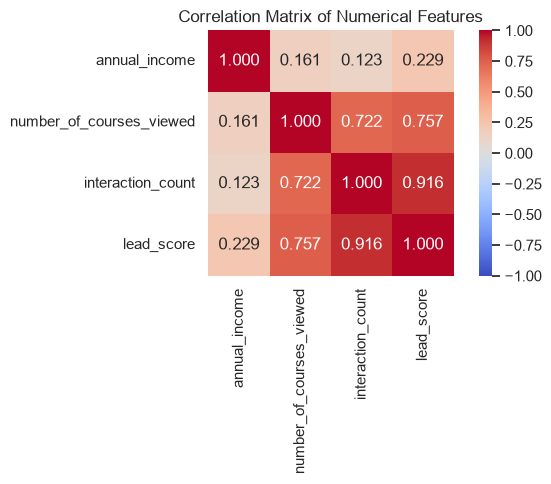

In [68]:
corr_matrix = df_prepared[numerical_features].corr(method="pearson")
print("Correlation matrix:")
display(corr_matrix)

candidate_pairs = [
    ("interaction_count", "lead_score"),
    ("number_of_courses_viewed", "lead_score"),
    ("number_of_courses_viewed", "interaction_count"),
    ("annual_income", "interaction_count"),
]

print("\nCandidate pairs and their correlations:")
for f1, f2 in candidate_pairs:
    corr_val = corr_matrix.loc[f1, f2]
    print(f"  {f1} & {f2}: {corr_val:.4f} (abs: {abs(corr_val):.4f})")

best_pair = max(candidate_pairs, key=lambda pair: abs(corr_matrix.loc[pair[0], pair[1]]))
print(f"\nPair with the biggest correlation: {best_pair[0]} and {best_pair[1]} ({corr_matrix.loc[best_pair[0], best_pair[1]]:.4f})")

# Visualize correlation matrix
plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".3f", square=True)
plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

**Answer:** `interaction_count` and `lead_score` (correlation: ~0.9157)

## Split the Data

Split the data with these exact calls:
```python
df_full_train, df_test = train_test_split(df_prepared, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)
```
Make sure that the target value `converted` is not in your dataframe.

In [69]:
# Split the data (60% train / 20% validation / 20% test)
df_full_train, df_test = train_test_split(df_prepared, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.pop(TARGET).values
y_val = df_val.pop(TARGET).values
y_test = df_test.pop(TARGET).values

print(f"Training set:   {df_train.shape[0]} samples")
print(f"Validation set: {df_val.shape[0]} samples")
print(f"Test set:       {df_test.shape[0]} samples")

Training set:   3000 samples
Validation set: 1000 samples
Test set:       1000 samples


### Question 3: Mutual Information

- Calculate the mutual information score between `converted` and other categorical variables in the dataset. Use the training set only.
- Round the scores to 2 decimals using `round(score, 2)`.

Which of these variables has the biggest mutual information score?

- `industry`
- `location`
- `lead_source`
- `employment_status`

In [70]:
def calculate_mi(series):
    return mutual_info_score(series, y_train)

mi_scores = df_train[categorical_features].apply(calculate_mi)
mi_scores_rounded = mi_scores.round(2).sort_values(ascending=False)

print("Mutual Information Scores (rounded to 2 decimals):")
for col, val in mi_scores_rounded.items():
    print(f"  {col}: {val} (exact: {mi_scores[col]:.4f})")

highest_mi_col = mi_scores.idxmax()
print(f"\nVariable with the biggest mutual information score: {highest_mi_col} ({mi_scores_rounded[highest_mi_col]})")

Mutual Information Scores (rounded to 2 decimals):
  lead_source: 0.03 (exact: 0.0343)
  employment_status: 0.02 (exact: 0.0190)
  industry: 0.0 (exact: 0.0020)
  location: 0.0 (exact: 0.0010)

Variable with the biggest mutual information score: lead_source (0.03)


**Answer:** `lead_source` (MI score: 0.03)

### Question 4: Logistic Regression Accuracy

- Now let's train a logistic regression.
- Remember that we have several categorical variables in the dataset. Include them using one-hot encoding via `DictVectorizer(sparse=False)`.
- Fit the model on the training dataset.
  - Parameters: `model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)`
- Calculate the accuracy on the validation dataset and round it to 2 decimal digits.

What accuracy did you get?

- 0.55
- 0.65
- 0.75
- 0.85

In [71]:
dv = DictVectorizer(sparse=False)

train_dict = df_train.to_dict(orient="records")
val_dict = df_val.to_dict(orient="records")

X_train = dv.fit_transform(train_dict)
X_val = dv.transform(val_dict)

model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_val)
original_accuracy = accuracy_score(y_val, y_pred)

print(f"Validation accuracy (exact):   {original_accuracy:.4f}")
print(f"Validation accuracy (rounded): {round(original_accuracy, 2)}")

Validation accuracy (exact):   0.6450
Validation accuracy (rounded): 0.65


**Answer:** `0.65`

### Question 5: Feature Elimination

- Let's find the least useful feature using the *feature elimination* technique.
- Train a model using the same features and parameters as in Q4 (without rounding).
- Now exclude each feature from this set and train a model without it. Record the accuracy for each model.
- For each feature, calculate the difference between the original accuracy and the accuracy without the feature.

Which of the following features has the smallest difference?

- `'lead_source'`
- `'number_of_courses_viewed'`
- `'interaction_count'`

> **Note**: The difference doesn't have to be positive.

In [72]:
candidate_features = ['lead_source', 'number_of_courses_viewed', 'interaction_count']
differences = {}

print(f"Original accuracy: {original_accuracy:.4f}\n")

for feature in candidate_features:
    df_train_sub = df_train.drop(columns=[feature])
    df_val_sub = df_val.drop(columns=[feature])
    
    dv_sub = DictVectorizer(sparse=False)
    X_train_sub = dv_sub.fit_transform(df_train_sub.to_dict(orient="records"))
    X_val_sub = dv_sub.transform(df_val_sub.to_dict(orient="records"))
    
    model_sub = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000, random_state=42)
    model_sub.fit(X_train_sub, y_train)
    
    y_pred_sub = model_sub.predict(X_val_sub)
    acc_sub = accuracy_score(y_val, y_pred_sub)
    
    diff = original_accuracy - acc_sub
    differences[feature] = {
        "accuracy": acc_sub,
        "difference": diff,
        "abs_difference": abs(diff)
    }
    print(f"Without '{feature}':")
    print(f"  Accuracy:       {acc_sub:.4f}")
    print(f"  Difference:     {diff:.4f}")
    print(f"  Abs difference: {abs(diff):.4f}\n")

smallest_diff_feature = min(candidate_features, key=lambda f: differences[f]["abs_difference"])
print(f"Feature with the smallest difference: '{smallest_diff_feature}' (|diff| = {differences[smallest_diff_feature]['abs_difference']:.4f})")

Original accuracy: 0.6450

Without 'lead_source':
  Accuracy:       0.6420
  Difference:     0.0030
  Abs difference: 0.0030

Without 'number_of_courses_viewed':
  Accuracy:       0.6430
  Difference:     0.0020
  Abs difference: 0.0020

Without 'interaction_count':
  Accuracy:       0.6010
  Difference:     0.0440
  Abs difference: 0.0440

Feature with the smallest difference: 'number_of_courses_viewed' (|diff| = 0.0020)


**Answer:** `'number_of_courses_viewed'` (difference: `0.0020`)

### Question 6: Regularized Logistic Regression (Tuning C)

- Now let's train a regularized logistic regression.
- Let's try the following values of the parameter `C`: `[0.000001, 0.00001, 0.0001, 0.001]`.
- Train models using all the features as in Q4.
- Calculate the accuracy on the validation dataset and round it to 3 decimal digits.

Which of these `C` leads to the best accuracy on the validation set?

- 0.000001
- 0.00001
- 0.0001
- 0.001

> **Note**: If there are multiple options, select the smallest `C`.

In [73]:
C_values = [0.000001, 0.00001, 0.0001, 0.001]
c_results = {}

for C in C_values:
    model_c = LogisticRegression(solver="liblinear", C=C, max_iter=1000, random_state=42)
    model_c.fit(X_train, y_train)
    
    y_pred_c = model_c.predict(X_val)
    acc_c = accuracy_score(y_val, y_pred_c)
    acc_c_round = round(acc_c, 3)
    c_results[C] = {
        "exact": acc_c,
        "rounded": acc_c_round
    }
    print(f"C = {C:<8}: Accuracy = {acc_c:.4f} -> Rounded: {acc_c_round:.3f}")

best_C = max(C_values, key=lambda c: (c_results[c]["rounded"], -c))
print(f"\nBest parameter C: {best_C} (Validation Accuracy: {c_results[best_C]['rounded']:.3f})")

C = 1e-06   : Accuracy = 0.5980 -> Rounded: 0.598
C = 1e-05   : Accuracy = 0.5980 -> Rounded: 0.598


C = 0.0001  : Accuracy = 0.6130 -> Rounded: 0.613
C = 0.001   : Accuracy = 0.6450 -> Rounded: 0.645

Best parameter C: 0.001 (Validation Accuracy: 0.645)


**Answer:** `0.001` (Validation accuracy: 0.645)